# Ecuación de Poisson comóvil en 2D — LFIS428, Grupo 3

Este cuaderno compila, valida y usa el código `src/poisson_comovil_cpu.c`, la versión periódica (cosmológica) del código de referencia del curso. Contenido:

1. Resumen de la física
2. El código C periódico
3. Validación con un modo exacto
4. Número de iteraciones frente a la teoría
5. Campo cosmológico: densidad, potencial y espectros
6. Para qué sirve: simulación *particle-mesh* 2D
7. Siguiente paso: CUDA

Las figuras se guardan en `figuras/` (PNG y PDF) para el README y el informe. Los números entre corchetes remiten a las referencias al final.

**Cómo correrlo.** En VS Code, abre el cuaderno desde la carpeta `notebooks/` del repositorio (necesitas `gcc`, `numpy` y `matplotlib`). En Google Colab, ejecuta primero `!git clone https://github.com/Robboppen/Proyecto-GPU-Poisson-C-movil.git` y luego `%cd Proyecto-GPU-Poisson-C-movil/notebooks`.

In [1]:
import os, re, shutil, subprocess, time
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "savefig.bbox": "tight"})

RAIZ = os.path.abspath("..")                  # raíz del repositorio
SRC = os.path.join(RAIZ, "src")
FIG = os.path.join(RAIZ, "figuras")
TRABAJO = os.path.join(RAIZ, "notebooks", "salidas")   # archivos temporales (ignorados por git)
os.makedirs(FIG, exist_ok=True)
os.makedirs(TRABAJO, exist_ok=True)
assert os.path.exists(os.path.join(SRC, "poisson_comovil_cpu.c")), "Abre el cuaderno desde la carpeta notebooks/ del repositorio"

def guardar(fig, nombre):
    # Guarda la figura en PNG (README) y PDF (informe LaTeX)
    fig.savefig(os.path.join(FIG, nombre + ".png"), dpi=160)
    fig.savefig(os.path.join(FIG, nombre + ".pdf"))

print("gcc:", shutil.which("gcc"))
print("Figuras en:", FIG)

gcc: /usr/bin/gcc
Figuras en: /home/claude/repo/figuras


## 1. Resumen de la física

La derivación completa está en el `README.md` y en el informe. Las ecuaciones que usa este cuaderno son:

**Movimiento y Poisson comóviles** [1, 2]. Con $\mathbf r = a(t)\,\mathbf x$, el fondo homogéneo genera la expansión y lo que queda es

$$
\ddot{\mathbf x} + 2H\dot{\mathbf x} = -\frac{1}{a^2}\nabla_x\phi,
\qquad
\nabla_x^2\phi = \frac32\,\frac{\Omega_m H_0^2}{a}\,\delta .
$$

**Unidades de código** [7]. Con $\tilde{\mathbf x} = \mathbf x/L$ y $\tilde\phi = \phi/(H_0L)^2$, la ecuación queda $\nabla^2\tilde\phi = \tfrac32(\Omega_m/a)\,\delta$: es el $\nabla^2 u = f$ del código, con $f = \tfrac32(\Omega_m/a)(\delta - \langle\delta\rangle)$ en una caja periódica.

**Crecimiento lineal** [1, 3]. $\ddot\delta + 2H\dot\delta = 4\pi G\bar\rho\,\delta$; en Einstein–de Sitter $\delta \propto a$ y $\phi \propto a^2\bar\rho\,\delta =$ constante.

## 2. El código C periódico

Cambios respecto al código de referencia `src/poisson_cpu.c`:

| Cambio | Por qué |
|---|---|
| $h = 1/N$; vecinos con módulo (`mas`, `menos`, `vecinos`) | La caja cosmológica no tiene borde: se repite. |
| Se actualizan **todos** los puntos | No hay puntos de borde fijos. |
| `f = 1.5*Om/a*(delta - <delta>)` | Condición de compatibilidad $\sum f = 0$: sin ella no hay solución. |
| `restar_promedio(u)` en cada chequeo | $\phi$ está definido salvo una constante (modo cero). |
| $\omega = 2/\big(1+\sin\pi h\,\sqrt{1+\cos^2\pi h}\big)$ | El modo de error más lento es $(1,0)$, con $\rho_J = \cos^2(\pi h)$ [15]. |
| `modo 0`: test de un modo; `modo 1`: lee `delta.bin` | Validación con solución exacta y campo cosmológico realista. |

Compilamos desde `src/` y ejecutamos en `notebooks/salidas/`.

In [2]:
EXE = os.path.join(TRABAJO, "poisson_comovil_cpu.x")
r = subprocess.run(["gcc", "-O2", os.path.join(SRC, "poisson_comovil_cpu.c"), "-lm", "-o", EXE],
                   capture_output=True, text=True)
print(r.stderr or "Compilado OK")

def correr(N, metodo=2, tol=1e-10, modo=0, Om=0.3, a=1.0):
    # Ejecuta el código C en la carpeta de trabajo y devuelve su salida de texto
    args = [EXE, str(N), str(metodo), str(tol), str(modo), str(Om), str(a)]
    return subprocess.run(args, capture_output=True, text=True, cwd=TRABAJO).stdout

print(correr(128))

Compilado OK
Poisson comóvil 2D periódico: N = 128, método = SOR rojo-negro (w = 1.932925), tol = 1.0e-10, Om = 0.300, a = 1.000, <delta> = -2.15e-18
Iteraciones: 400, residuo relativo = 2.115e-11
Tiempo de cómputo: 0.012 s (0.030 ms por iteración)
Error vs. solución discreta exacta (solver):        1.320e-13
Error vs. solución continua (discretización, ~h^2): 6.830e-04 (h^2 = 6.104e-05)



## 3. Validación con un modo exacto

Con $\delta = \cos(2\pi x)\cos(4\pi y)$, el laplaciano discreto actúa sobre cada coseno como

$$
\frac{\cos k(x+h) + \cos k(x-h) - 2\cos kx}{h^2} = -\frac{4}{h^2}\sin^2\!\frac{kh}{2}\,\cos kx ,
$$

así que hay dos soluciones de referencia: la **discreta** mide el error del *solver* (debe ser del orden de la tolerancia) y la **continua**, con autovalor $-4\pi^2(m^2+n^2)$, mide el error de *discretización* (debe ser $O(h^2)$) [15].

 N    error solver   error discretización   cociente
  32   2.74e-13       1.099e-02           nan
  64   1.70e-13       2.735e-03           4.02
 128   1.32e-13       6.830e-04           4.00
 256   1.02e-13       1.707e-04           4.00
 512   1.43e-13       4.267e-05           4.00


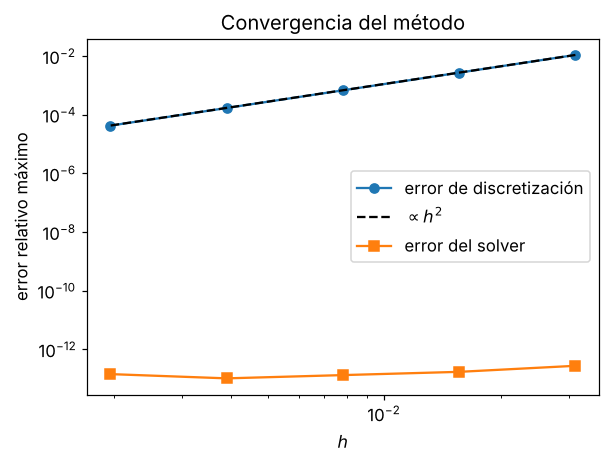

In [3]:
Ns = [32, 64, 128, 256, 512]
err_solver, err_disc = [], []
for N in Ns:
    out = correr(N, metodo=2, tol=1e-10, modo=0)
    err_solver.append(float(re.search(r"discreta exacta \(solver\):\s+([\d.e+-]+)", out).group(1)))
    err_disc.append(float(re.search(r"~h\^2\):\s+([\d.e+-]+)", out).group(1)))

h = 1/np.array(Ns)
print(" N    error solver   error discretización   cociente")
for i, N in enumerate(Ns):
    q = err_disc[i-1]/err_disc[i] if i else float("nan")
    print(f"{N:4d}   {err_solver[i]:.2e}       {err_disc[i]:.3e}           {q:.2f}")

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.loglog(h, err_disc, "o-", label="error de discretización")
ax.loglog(h, err_disc[0]*(h/h[0])**2, "k--", label=r"$\propto h^2$")
ax.loglog(h, err_solver, "s-", label="error del solver")
ax.set_xlabel("$h$"); ax.set_ylabel("error relativo máximo"); ax.legend()
ax.set_title("Convergencia del método")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
guardar(fig, "convergencia"); plt.show()

**Qué muestra.** El error de discretización (círculos) sigue la recta $\propto h^2$: al duplicar $N$ baja exactamente 4 veces, como corresponde a un esquema de segundo orden. El error del solver (cuadrados) queda en $10^{-15}$–$10^{-13}$, es decir, la iteración resuelve el sistema discreto hasta la precisión de la máquina; todo el error frente a la física viene de la discretización.

## 4. Número de iteraciones frente a la teoría

Para Jacobi, cada modo $e_{p,q}$ del error se multiplica en cada iteración por $\tfrac12[\cos(2\pi p h)+\cos(2\pi q h)]$ (caso periódico). Excluyendo el modo cero, el más lento es $(1,0)$, con $\rho_J = \cos^2(\pi h)\approx 1-\pi^2h^2$ [15]:

$$
k_{\text{Jacobi}} \approx \frac{\ln(1/\varepsilon)}{\pi^2h^2} \propto N^2,
\qquad
k_{\text{GS}} \approx \tfrac12 k_{\text{Jacobi}},
\qquad
k_{\text{SOR}} \propto N .
$$

La fuente es un campo gaussiano aleatorio, que excita todos los modos.

N=  32  Jacobi    1900 (pred.     1911)  GS    1000  SOR   100
N=  64  Jacobi    7200 (pred.     7645)  GS    3700  SOR   200
N= 128  Jacobi   26800 (pred.    30579)  GS   13700  SOR   400
N= 256  Jacobi  114600 (pred.   122317)  GS   58500  SOR   800


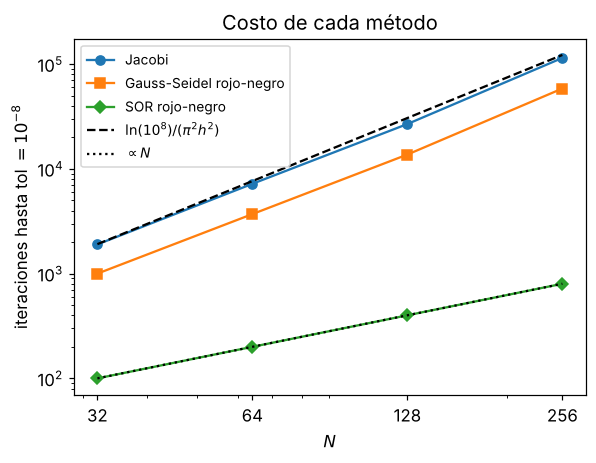

In [4]:
def generar_delta(N, n_s=-1.0, sigma=1.0, semilla=42):
    # Campo gaussiano periódico con P(k) ∝ k^n_s exp(-(k/kc)^2).
    # Receta: ruido blanco -> FFT -> multiplicar por sqrt(P(k)) -> FFT inversa.
    rng = np.random.default_rng(semilla)
    k1 = 2*np.pi*np.fft.fftfreq(N, d=1.0/N)
    kx, ky = np.meshgrid(k1, k1, indexing="xy")
    k = np.sqrt(kx**2 + ky**2); k[0, 0] = 1.0
    kc = 2*np.pi*N/8                                 # corte suave: evita ruido de malla
    P = k**n_s * np.exp(-(k/kc)**2); P[0, 0] = 0.0   # <delta> = 0
    delta = np.fft.ifft2(np.fft.fft2(rng.normal(size=(N, N))) * np.sqrt(P)).real
    delta *= sigma/delta.std()
    with open(os.path.join(TRABAJO, "delta.bin"), "wb") as f:   # mismo formato que el código C
        np.array([N, N, 1, 8], dtype=np.int32).tofile(f)
        delta.astype(np.float64).tofile(f)
    return delta

metodos = [(0, "Jacobi"), (1, "Gauss-Seidel rojo-negro"), (2, "SOR rojo-negro")]
Ns_it = [32, 64, 128, 256]
iters = {nombre: [] for _, nombre in metodos}
for N in Ns_it:
    generar_delta(N)
    for m, nombre in metodos:
        out = correr(N, metodo=m, tol=1e-8, modo=1)
        iters[nombre].append(int(re.search(r"Iteraciones: (\d+)", out).group(1)))

Na = np.array(Ns_it)
pred = np.log(1e8)/(np.pi**2/Na**2)
for i, N in enumerate(Ns_it):
    print(f"N={N:4d}  Jacobi {iters['Jacobi'][i]:7d} (pred. {pred[i]:8.0f})  "
          f"GS {iters['Gauss-Seidel rojo-negro'][i]:7d}  SOR {iters['SOR rojo-negro'][i]:5d}")

fig, ax = plt.subplots(figsize=(6, 4.2))
for nombre, mk in zip(iters, "osD"):
    ax.loglog(Na, iters[nombre], mk + "-", label=nombre)
ax.loglog(Na, pred, "k--", label=r"$\ln(10^8)/(\pi^2h^2)$")
ax.loglog(Na, iters["SOR rojo-negro"][0]*Na/Na[0], "k:", label=r"$\propto N$")
ax.set_xlabel("$N$"); ax.set_ylabel("iteraciones hasta tol $=10^{-8}$"); ax.legend(fontsize=9)
ax.set_title("Costo de cada método")
ax.xaxis.set_minor_formatter(plt.NullFormatter()); ax.set_xticks(Ns_it, [str(n) for n in Ns_it])
guardar(fig, "iteraciones"); plt.show()

**Qué muestra.** Jacobi (círculos) sigue la predicción $\propto N^2$ (línea discontinua); Gauss-Seidel rojo-negro necesita la mitad, porque su factor de contracción es $\rho_J^2$; SOR crece solo $\propto N$ (línea punteada). Con $N=256$, SOR necesita unas 140 veces menos iteraciones que Jacobi. El trabajo total es iteraciones × $N^2$ puntos, así que Jacobi cuesta $\sim N^4$ y SOR $\sim N^3$; multigrid llegaría a $\sim N^2$ [14].

## 5. Campo cosmológico: densidad, potencial y espectros

Resolvemos con SOR para un campo gaussiano en $N = 256$ y comparamos con la solución espectral del **mismo** problema discreto: en Fourier, el laplaciano de 5 puntos es diagonal con autovalor $\lambda_{\mathbf k} = -\tfrac{4}{h^2}\left[\sin^2\tfrac{k_xh}{2} + \sin^2\tfrac{k_yh}{2}\right]$ [4].

In [5]:
N, Om, a = 256, 0.3, 1.0
generar_delta(N)
print(correr(N, metodo=2, tol=1e-10, modo=1, Om=Om, a=a))

with open(os.path.join(TRABAJO, "salida_cpu.bin"), "rb") as f:
    nx, ny, nc, nb = (int(v) for v in np.fromfile(f, dtype=np.int32, count=4))  # int(): evita overflow de int32
    phi, delta = np.fromfile(f, dtype=np.float64).reshape(nc, ny, nx)

h = 1.0/N; pref = 1.5*Om/a
k1 = 2*np.pi*np.fft.fftfreq(N, d=h)
kx, ky = np.meshgrid(k1, k1, indexing="xy")
lam = -4/h**2*(np.sin(kx*h/2)**2 + np.sin(ky*h/2)**2); lam[0, 0] = 1.0
phik = pref*np.fft.fft2(delta - delta.mean())/lam; phik[0, 0] = 0.0
phi_fft = np.fft.ifft2(phik).real
print(f"Diferencia relativa máxima iterativo vs FFT: {np.abs(phi-phi_fft).max()/np.abs(phi_fft).max():.2e}")

Poisson comóvil 2D periódico: N = 256, método = SOR rojo-negro (w = 1.965884), tol = 1.0e-10, Om = 0.300, a = 1.000, <delta> = 6.06e-16
Iteraciones: 900, residuo relativo = 3.044e-11
Tiempo de cómputo: 0.118 s (0.131 ms por iteración)

Diferencia relativa máxima iterativo vs FFT: 8.03e-13


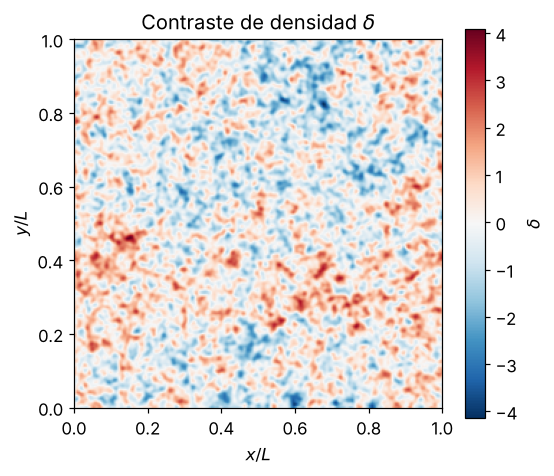

In [6]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(delta, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r")
plt.colorbar(im, ax=ax, label=r"$\delta$")
ax.set_xlabel(r"$x/L$"); ax.set_ylabel(r"$y/L$"); ax.set_title(r"Contraste de densidad $\delta$")
guardar(fig, "delta"); plt.show()

**Qué muestra.** Un campo gaussiano aleatorio con $P(k)\propto k^{-1}$ y $\sigma_\delta = 1$: regiones sobredensas (rojo) y subdensas (azul) en todas las escalas hasta el corte. Es la fuente $\delta$ que recibe el solver; en una simulación vendría del depósito de partículas.

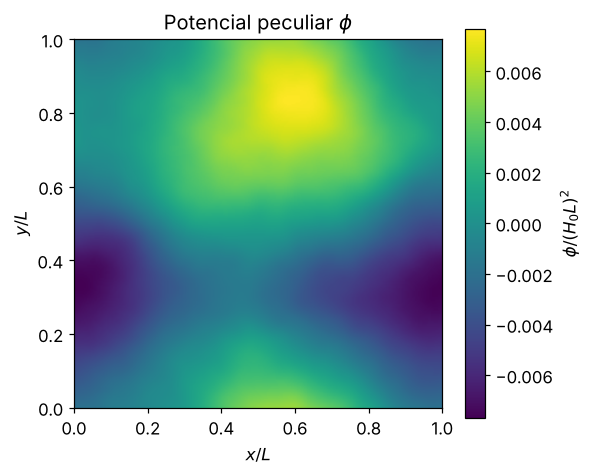

In [7]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(phi, origin="lower", extent=[0, 1, 0, 1], cmap="viridis")
plt.colorbar(im, ax=ax, label=r"$\phi/(H_0L)^2$")
ax.set_xlabel(r"$x/L$"); ax.set_ylabel(r"$y/L$"); ax.set_title(r"Potencial peculiar $\phi$")
guardar(fig, "potencial"); plt.show()

**Qué muestra.** El potencial que genera ese campo. Es mucho más suave que $\delta$ porque Poisson divide por $k^2$ en Fourier: las escalas pequeñas quedan suprimidas y dominan las ondulaciones del tamaño de la caja. Las zonas oscuras son pozos de potencial ($\phi<0$), hacia donde fluye la materia [1].

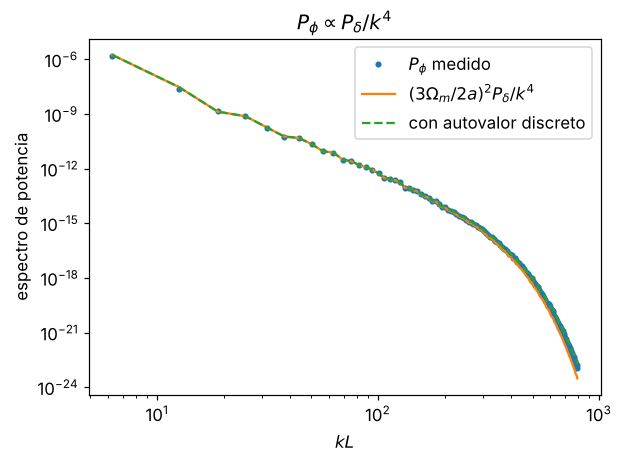

In [8]:
kmod = np.sqrt(kx**2 + ky**2)
bordes = np.arange(0.5, N//2, 1.0)*2*np.pi
idx = np.digitize(kmod.ravel(), bordes)
def espectro(campo):
    p = (np.abs(np.fft.fft2(campo))**2/float(N)**4).ravel()
    return np.array([p[idx == i].mean() for i in range(1, len(bordes))])
kc = 0.5*(bordes[1:] + bordes[:-1])
Pd, Pp = espectro(delta), espectro(phi)
P_cont = pref**2*Pd/kc**4
P_disc = pref**2*Pd/(4*N**2*np.sin(kc/(2*N))**2)**2

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.loglog(kc, Pp, ".", label=r"$P_\phi$ medido")
ax.loglog(kc, P_cont, "-", label=r"$(3\Omega_m/2a)^2P_\delta/k^4$")
ax.loglog(kc, P_disc, "--", label="con autovalor discreto")
ax.set_xlabel(r"$kL$"); ax.set_ylabel("espectro de potencia"); ax.legend()
ax.set_title(r"$P_\phi \propto P_\delta/k^4$")
guardar(fig, "espectros"); plt.show()

**Qué muestra.** El espectro del potencial medido (puntos) sigue la predicción de Poisson $P_\phi = (3\Omega_m/2a)^2P_\delta/k^4$ [3]. En $k$ alto se separa levemente de $k^{-4}$ porque el laplaciano discreto tiene autovalor $\tfrac{4}{h^2}\sin^2(kh/2) < k^2$; con el autovalor discreto (línea discontinua) el acuerdo es completo. La diferencia con la solución FFT es $\sim10^{-12}$.

## 6. Para qué sirve: simulación *particle-mesh* 2D

Una simulación cosmológica de N-cuerpos es una solución Monte Carlo de Vlasov–Poisson [2, 4]. En cada paso:

1. **Depósito CIC**: cada partícula reparte su masa entre las 4 celdas vecinas, lo que da $\delta(\mathbf x)$ [4].
2. **Poisson comóvil**, que da $\phi$ (aquí con FFT para que sea rápido; es el paso que el proyecto acelera en GPU).
3. **Fuerza** $\mathbf g = -\nabla\phi$ con diferencias centradas, interpolada a las partículas con CIC.
4. **Leapfrog KDK** usando $a$ como tiempo. Con el momento $\mathbf p = a^2\dot{\mathbf x}$ y $dt = da/(aH)$ [5]:

$$
\frac{d\mathbf p}{da} = -\frac{\nabla\phi}{aH},\qquad \frac{d\mathbf x}{da} = \frac{\mathbf p}{a^3H},\qquad H = H_0\,a^{-3/2}\ \ (\text{EdS}).
$$

**Condiciones iniciales de Zel'dovich** [18]: $\mathbf x = \mathbf q + D(a)\,\boldsymbol\psi(\mathbf q)$ con $\delta = -\nabla\cdot\boldsymbol\psi$, es decir $\hat{\boldsymbol\psi}_{\mathbf k} = i\mathbf k\,\hat\delta_{\mathbf k}/k^2$, y $D = a$ en Einstein–de Sitter.

Es un modelo de juguete: dinámica 2D con los coeficientes de 3D. El algoritmo es el de GADGET o RAMSES [5, 6].

In [9]:
Ng = Np = 256
rng = np.random.default_rng(3)
k1 = 2*np.pi*np.fft.fftfreq(Ng, 1/Ng)
KX, KY = np.meshgrid(k1, k1, indexing="ij"); K2 = KX**2 + KY**2; K2[0, 0] = 1
P = np.sqrt(K2)**-1.0*np.exp(-K2/(2*np.pi*40)**2); P[0, 0] = 0
dk = np.fft.fft2(rng.normal(size=(Ng, Ng)))*np.sqrt(P)
sigma_lin = 0.9
dk *= sigma_lin/np.fft.ifft2(dk).real.std()     # sigma lineal en a = 1

psx = np.fft.ifft2(1j*KX*dk/K2).real; psy = np.fft.ifft2(1j*KY*dk/K2).real
q = (np.arange(Np) + 0.5)/Np; QX, QY = np.meshgrid(q, q, indexing="ij")
H = lambda a: a**-1.5
a = 0.02
x = (QX + a*psx) % 1; y = (QY + a*psy) % 1
px = a**2*(a*H(a))*psx; py = a**2*(a*H(a))*psy

def pesos(x, y):
    fx = x*Ng - 0.5; fy = y*Ng - 0.5
    i = np.floor(fx).astype(int); j = np.floor(fy).astype(int)
    return i, j, fx - i, fy - j

def cic(x, y):
    g = np.zeros((Ng, Ng)); i, j, tx, ty = pesos(x, y)
    for di, wx in ((0, 1 - tx), (1, tx)):
        for dj, wy in ((0, 1 - ty), (1, ty)):
            np.add.at(g, ((i + di) % Ng, (j + dj) % Ng), wx*wy)
    return g/g.mean() - 1

def interp(F, x, y):
    i, j, tx, ty = pesos(x, y); out = 0
    for di, wx in ((0, 1 - tx), (1, tx)):
        for dj, wy in ((0, 1 - ty), (1, ty)):
            out = out + F[(i + di) % Ng, (j + dj) % Ng]*wx*wy
    return out

lam = -(4*Ng**2)*(np.sin(KX/(2*Ng))**2 + np.sin(KY/(2*Ng))**2); lam[0, 0] = 1
def fuerza(x, y, a):
    d = cic(x, y)
    phik = 1.5/a*np.fft.fft2(d)/lam; phik[0, 0] = 0     # <- Poisson comóvil (Om = 1)
    phi = np.fft.ifft2(phik).real
    gx = -(np.roll(phi, -1, 0) - np.roll(phi, 1, 0))*Ng/2
    gy = -(np.roll(phi, -1, 1) - np.roll(phi, 1, 1))*Ng/2
    return interp(gx, x, y), interp(gy, x, y), d, phi

hist_a, hist_sd, hist_sp, snaps = [], [], [], {}
da = 0.004; t0 = time.time()
gx, gy, d, phi_pm = fuerza(x, y, a)
while a < 1.0 - 1e-9:
    hist_a.append(a); hist_sd.append(d.std()); hist_sp.append(phi_pm.std())
    for ao in (0.1, 0.3):
        if abs(a - ao) < da/2: snaps[ao] = (x.copy(), y.copy(), phi_pm.copy())
    px += gx/(a*H(a))*da/2; py += gy/(a*H(a))*da/2                         # kick
    am = a + da/2
    x = (x + px/(am**3*H(am))*da) % 1; y = (y + py/(am**3*H(am))*da) % 1   # drift
    a += da
    gx, gy, d, phi_pm = fuerza(x, y, a)
    px += gx/(a*H(a))*da/2; py += gy/(a*H(a))*da/2                         # kick
hist_a.append(a); hist_sd.append(d.std()); hist_sp.append(phi_pm.std())
snaps[1.0] = (x, y, phi_pm)
print(f"{len(hist_a)} pasos, {time.time() - t0:.1f} s")

# Resultados para otras figuras (presentación)
np.savez(os.path.join(TRABAJO, "resultados.npz"), delta=delta, phi=phi, kc=kc, Pp=Pp, P_cont=P_cont,
         P_disc=P_disc, h=h, Ns=Ns, err_disc=err_disc, err_solver=err_solver, Ns_it=Ns_it,
         it_j=iters["Jacobi"], it_gs=iters["Gauss-Seidel rojo-negro"], it_sor=iters["SOR rojo-negro"],
         hist_a=hist_a, hist_sd=hist_sd, hist_sp=hist_sp, sigma_lin=sigma_lin,
         **{f"snap{ao}_{c}": v for ao, s in snaps.items() for c, v in zip("xyp", s)})

246 pasos, 5.0 s


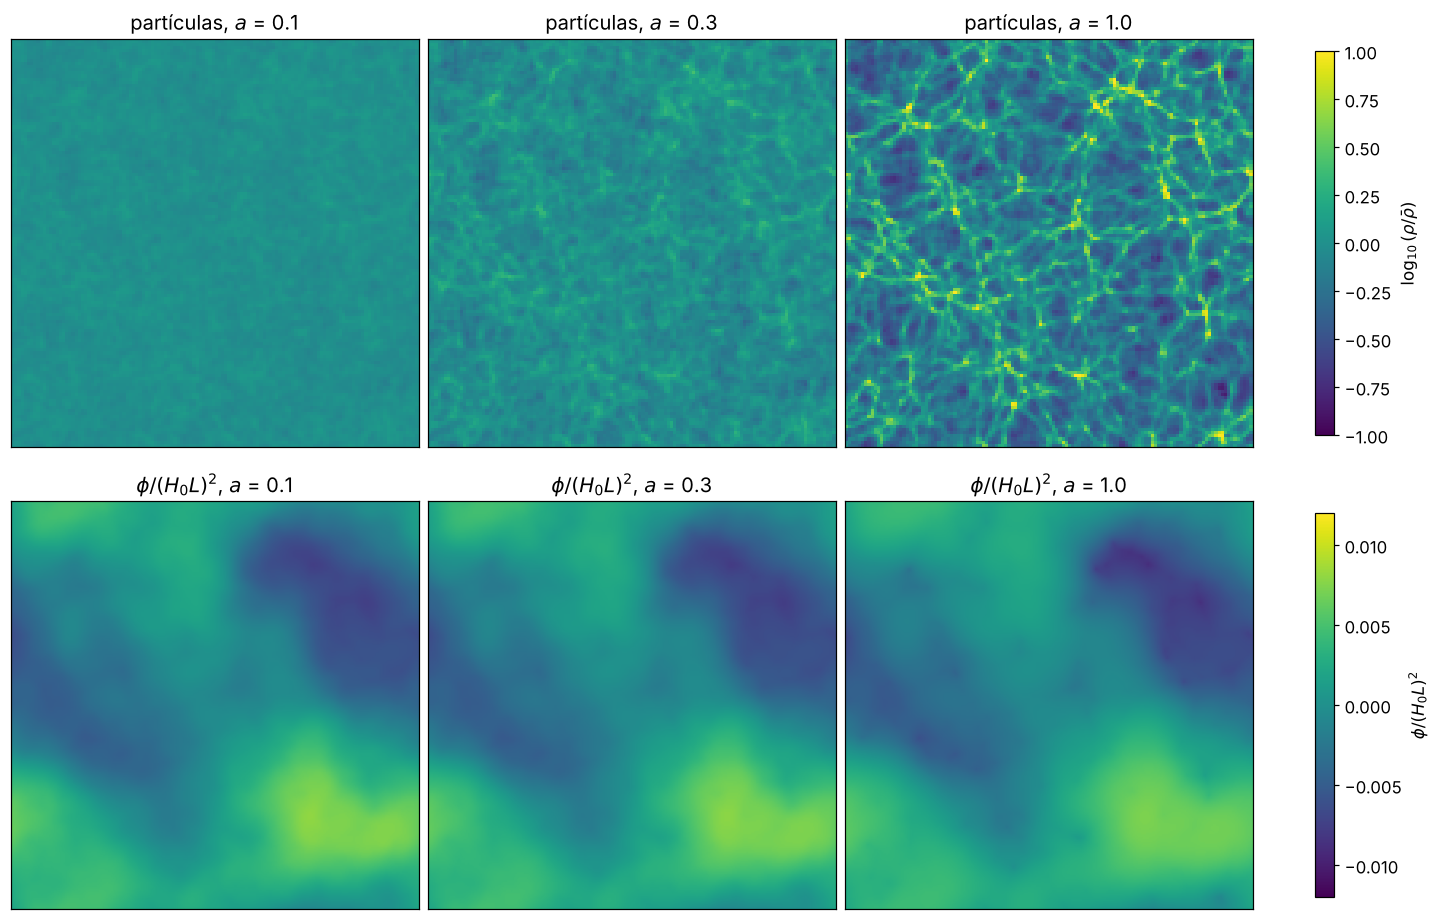

In [10]:
def densidad_particulas(X, Y, n=128):
    # Densidad de partículas con depósito CIC en una malla de n x n: log10(rho/rho_media)
    g = np.zeros((n, n)); fx = X.ravel()*n - 0.5; fy = Y.ravel()*n - 0.5
    i = np.floor(fx).astype(int); j = np.floor(fy).astype(int); tx = fx - i; ty = fy - j
    for di, wx in ((0, 1 - tx), (1, tx)):
        for dj, wy in ((0, 1 - ty), (1, ty)):
            np.add.at(g, ((i + di) % n, (j + dj) % n), wx*wy)
    return np.log10(np.clip(g/g.mean(), 0.1, None))

fig, ax = plt.subplots(2, 3, figsize=(13, 8.4), constrained_layout=True)
for c, ao in enumerate((0.1, 0.3, 1.0)):
    X, Y, ph = snaps[ao]
    imd = ax[0, c].imshow(densidad_particulas(X, Y).T, origin="lower", extent=[0, 1, 0, 1],
                          cmap="viridis", vmin=-1, vmax=1)
    ax[0, c].set_title(f"partículas, $a$ = {ao}")
    imp = ax[1, c].imshow(ph.T, origin="lower", extent=[0, 1, 0, 1], cmap="viridis",
                          vmin=-0.012, vmax=0.012)
    ax[1, c].set_title(rf"$\phi/(H_0L)^2$, $a$ = {ao}")
    for A in ax[:, c]: A.set_xticks([]); A.set_yticks([])
fig.colorbar(imd, ax=ax[0, :], shrink=0.9, label=r"$\log_{10}(\rho/\bar\rho)$")
fig.colorbar(imp, ax=ax[1, :], shrink=0.9, label=r"$\phi/(H_0L)^2$")
guardar(fig, "pm_evolucion"); plt.show()

**Qué muestra.** Arriba, la densidad de partículas, $\log_{10}(\rho/\bar\rho)$ obtenida con depósito CIC, en el mismo mapa de colores *viridis* que el potencial de abajo. En $a = 0.1$ la distribución es casi uniforme (verde, $\rho\approx\bar\rho$). En $a = 0.3$ aparecen las primeras sobredensidades. En $a = 1$ se ve la **red cósmica**: filamentos, nodos donde se cruzan y vacíos. Los filamentos aparecen porque el colapso es anisótropo: en la aproximación de Zel'dovich la densidad es $\bar\rho/[(1-D\lambda_1)(1-D\lambda_2)]$ y colapsa primero la dirección del autovalor mayor [18].

Abajo, el potencial en las mismas épocas: los tres mapas son casi iguales, y sus pozos (zonas oscuras) coinciden con los nodos y filamentos de arriba.

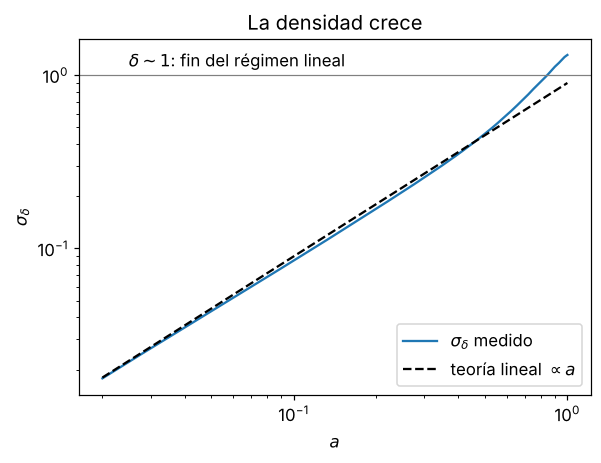

In [11]:
A = np.array(hist_a)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.loglog(A, hist_sd, label=r"$\sigma_\delta$ medido")
ax.loglog(A, sigma_lin*A, "k--", label=r"teoría lineal $\propto a$")
ax.axhline(1, color="gray", lw=0.8); ax.text(0.025, 1.12, r"$\delta\sim1$: fin del régimen lineal")
ax.set_xlabel("$a$"); ax.set_ylabel(r"$\sigma_\delta$"); ax.legend(loc="lower right")
ax.set_title("La densidad crece")
guardar(fig, "crecimiento_densidad"); plt.show()

**Qué muestra.** La desviación estándar de la densidad sigue la teoría lineal $\delta\propto a$ (recta de pendiente 1) hasta $\sigma_\delta\approx0.5$, confirmando $\ddot\delta + 2H\dot\delta = 4\pi G\bar\rho\,\delta$ [1, 3]. Después crece **más rápido**: es el régimen no lineal, donde los términos $\delta\,\mathbf v$ y $(\mathbf v\cdot\nabla)\mathbf v$ que se descartaron al linealizar dejan de ser pequeños, y donde la simulación es la única herramienta [2].

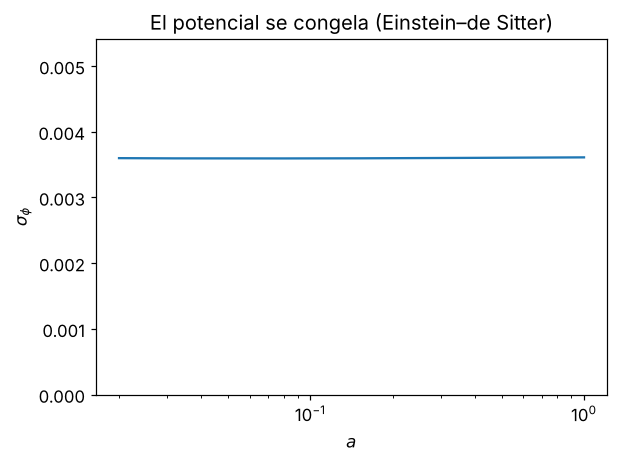

In [12]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.semilogx(A, hist_sp)
ax.set_ylim(0, 1.5*max(hist_sp))
ax.set_xlabel("$a$"); ax.set_ylabel(r"$\sigma_\phi$")
ax.set_title(r"El potencial se congela (Einstein–de Sitter)")
guardar(fig, "potencial_congelado"); plt.show()

**Qué muestra.** La dispersión del potencial es constante, $\sigma_\phi \approx 3.6\times10^{-3}$, de $a = 0.02$ a $a = 1$, como predice $\phi\propto a^2\bar\rho\,\delta\propto a^2 a^{-3}a$ [1]. Se mantiene incluso en el régimen no lineal, porque $\phi$ está dominado por escalas grandes, que siguen siendo lineales. Con energía oscura el crecimiento se frena y esta curva bajaría a bajo redshift: es el origen del efecto Sachs–Wolfe integrado [12].

## 7. Siguiente paso: CUDA

En Colab: *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*, y luego `!nvcc --version`. La versión 1 porta los kernels `jacobi` y `media_iteracion_rb` (un thread por punto, índices periódicos), la reducción del residuo y `restar_promedio`, manteniendo `u`, `f` y `delta` en la GPU.

## Referencias

1. P. J. E. Peebles, *The Large-Scale Structure of the Universe*, Princeton University Press (1980).
2. E. Bertschinger, Simulations of structure formation in the universe, *ARA&A* **36**, 599 (1998). [DOI](https://doi.org/10.1146/annurev.astro.36.1.599)
3. S. Dodelson & F. Schmidt, *Modern Cosmology*, 2.ª ed., Academic Press (2020).
4. R. W. Hockney & J. W. Eastwood, *Computer Simulation Using Particles*, IOP (1988).
5. V. Springel, The cosmological simulation code GADGET-2, *MNRAS* **364**, 1105 (2005). [arXiv:astro-ph/0505010](https://arxiv.org/abs/astro-ph/0505010)
6. R. Teyssier, Cosmological hydrodynamics with adaptive mesh refinement, *A&A* **385**, 337 (2002). [arXiv:astro-ph/0111367](https://arxiv.org/abs/astro-ph/0111367)
7. C. Barrera-Hinojosa & B. Li, GRAMSES. Part I, *JCAP* **01** (2020) 007. [arXiv:1905.08890](https://arxiv.org/abs/1905.08890)
12. R. K. Sachs & A. M. Wolfe, *ApJ* **147**, 73 (1967). [DOI](https://doi.org/10.1086/148982)
14. W. L. Briggs, V. E. Henson & S. F. McCormick, *A Multigrid Tutorial*, 2.ª ed., SIAM (2000).
15. W. H. Press et al., *Numerical Recipes*, 3.ª ed., Cambridge University Press (2007), §20.5.
18. Ya. B. Zel'dovich, *A&A* **5**, 84 (1970).

La numeración sigue la lista completa del `README.md`.